# Tugas: Deployment Model Klasifikasi Huruf BISINDO ke Hugging Face

* **Mata Kuliah**: Pembelajaran Mesin (RTI235004)
* **Topik Modul**: JS15 - Pipeline Machine Learning & Deployment
* **Nama**: Mohammad Al Hafis Hidayatulloh
* **NIM**: 254107023005
* **Kelas**: TI-3G

---

### Deskripsi Tugas
Tugas ini menerapkan *pipeline deployment* yang sama dengan studi kasus *Day vs Night* pada model **Project** sendiri, yaitu **klasifikasi 26 huruf alfabet Bahasa Isyarat Indonesia (BISINDO)** dari citra tangan.

Berbeda dengan Day vs Night yang memakai fitur HOG, proyek BISINDO memakai fitur **landmark tangan MediaPipe** (dari `extract_features.py` proyek kelompok):

| Indeks fitur | Isi |
|---|---|
| `0..62` | 21 titik (x, y, z) tangan primer, relatif terhadap pergelangan dan dibagi skala telapak |
| `63..125` | 21 titik (x, y, z) tangan sekunder (diisi nol jika hanya 1 tangan) |
| `126` | *flag* `is_two_handed` |

Artefak yang dihasilkan notebook ini (disimpan di folder `bisindo-project/`):

| Artefak | Kegunaan |
|---|---|
| `bisindo_model.h5` | Neural Network (Keras) dengan akurasi terbaik |
| `scaler.pkl` | `StandardScaler` hasil *fit* data training |
| `labels.json` | Pemetaan indeks output → huruf A–Z |
| `hand_landmarker.task` | Model MediaPipe untuk mengekstraksi landmark dari gambar upload |

Aplikasi Flask (`app.py`) menerima gambar, mengekstraksi landmark dengan fungsi yang **sama persis** dengan saat pembuatan dataset, menormalisasi dengan `scaler.pkl`, lalu memprediksi huruf menggunakan `bisindo_model.h5`.

### Langkah 1 - Import Library

In [1]:
import os
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import json, pickle, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


### Langkah 2 - Load Dataset Landmark BISINDO
Dataset `dataset_bisindo_landmarks.npz` adalah hasil ekstraksi `extract_features.py` dari 9.000+ citra BISINDO (citra yang tangannya tidak terdeteksi sudah dibuang).

In [2]:
DATA_PATH = Path('../Klasifikasi_Kelompok_1/dataset_bisindo_landmarks.npz')
data = np.load(DATA_PATH, allow_pickle=True)

X = data['X'].astype(np.float32)
labels = data['labels'].astype(str)
feature_names = data['feature_names']

print(f"Dimensi fitur X : {X.shape}")
print(f"Jumlah kelas    : {len(np.unique(labels))}")
print(f"Proporsi 2 tangan: {X[:, -1].mean() * 100:.1f}%")

Dimensi fitur X : (7893, 127)
Jumlah kelas    : 26
Proporsi 2 tangan: 45.6%


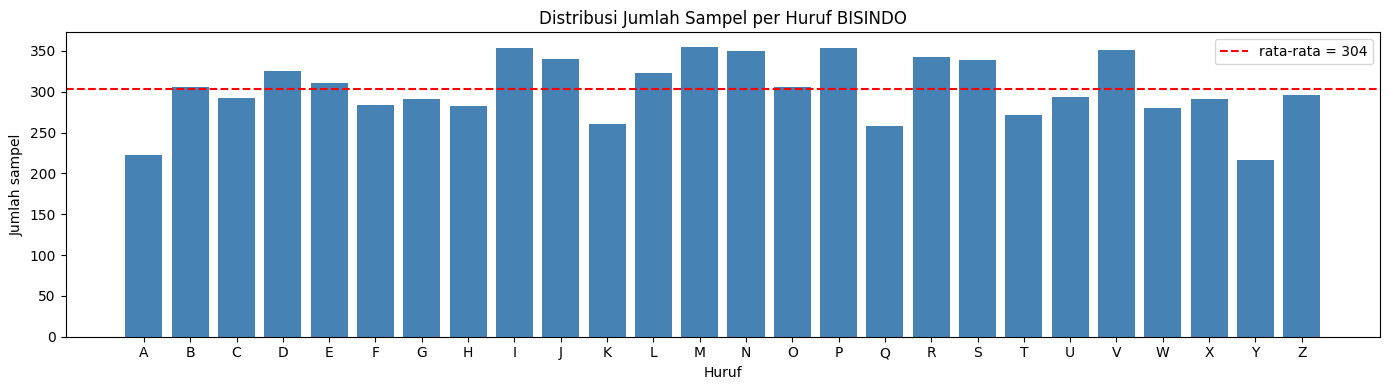

In [3]:
counts = pd.Series(labels).value_counts().sort_index()
plt.figure(figsize=(14, 4))
plt.bar(counts.index, counts.values, color='steelblue')
plt.axhline(counts.mean(), color='red', ls='--', label=f'rata-rata = {counts.mean():.0f}')
plt.title('Distribusi Jumlah Sampel per Huruf BISINDO')
plt.xlabel('Huruf'); plt.ylabel('Jumlah sampel'); plt.legend()
plt.tight_layout(); plt.show()

### Langkah 3 - Label Encoding & Split Data
Label huruf diubah menjadi indeks 0–25. Data dibagi secara **stratified** menjadi 70% train, 15% validation, dan 15% test agar proporsi tiap huruf tetap seimbang.

In [4]:
le = LabelEncoder()
y = le.fit_transform(labels)
class_names = [str(c) for c in le.classes_]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

Train: 5525 | Validation: 1184 | Test: 1184


### Langkah 4 - Normalisasi Fitur (StandardScaler)
Sama seperti praktikum, scaler hanya di-*fit* pada data training, kemudian parameter (mean & std) dipakai untuk validation, test, dan nanti untuk inferensi di server.

In [5]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)
print(f"Mean train: {X_train_s.mean():.4f} | Std train: {X_train_s.std():.4f}")

Mean train: 0.0000 | Std train: 0.9881


### Langkah 5 - Eksperimen Arsitektur Neural Network
Agar model yang di-*deploy* adalah model dengan akurasi terbaik, beberapa arsitektur *feedforward* dibandingkan. Semuanya memakai output **softmax 26 kelas**, *loss* `sparse_categorical_crossentropy`, optimizer Adam, serta **EarlyStopping** (memantau `val_loss`, mengembalikan bobot terbaik).

| Nama | Arsitektur |
|---|---|
| `MLP-128-64` | Dense 128 → Dense 64 (setara arsitektur praktikum) |
| `MLP-256-128-Dropout` | Dense 256 → Dropout 0.3 → Dense 128 → Dropout 0.3 |
| `MLP-512-256-128-BN` | (Dense → BatchNorm → Dropout) × 3 dengan 512, 256, 128 neuron |

In [6]:
def build_model(name, input_dim, n_classes):
    inp = layers.Input(shape=(input_dim,))
    if name == 'MLP-128-64':
        x = layers.Dense(128, activation='relu')(inp)
        x = layers.Dense(64, activation='relu')(x)
    elif name == 'MLP-256-128-Dropout':
        x = layers.Dense(256, activation='relu')(inp)
        x = layers.Dropout(0.3)(x)
        x = layers.Dense(128, activation='relu')(x)
        x = layers.Dropout(0.3)(x)
    elif name == 'MLP-512-256-128-BN':
        x = inp
        for units, drop in [(512, 0.4), (256, 0.3), (128, 0.2)]:
            x = layers.Dense(units)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation('relu')(x)
            x = layers.Dropout(drop)(x)
    out = layers.Dense(n_classes, activation='softmax')(x)
    model = models.Model(inp, out, name=name.replace('-', '_'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

ARCHS = ['MLP-128-64', 'MLP-256-128-Dropout', 'MLP-512-256-128-BN']
results, histories, trained = [], {}, {}

for name in ARCHS:
    tf.random.set_seed(SEED)
    m = build_model(name, X_train_s.shape[1], len(class_names))
    es = callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    h = m.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
              epochs=200, batch_size=64, callbacks=[es], verbose=0)
    val_acc = m.evaluate(X_val_s, y_val, verbose=0)[1]
    results.append({'model': name, 'params': m.count_params(),
                    'epochs': len(h.history['loss']), 'val_accuracy': val_acc})
    histories[name], trained[name] = h, m
    print(f"{name:22s} | params {m.count_params():7d} | epochs {len(h.history['loss']):3d} | val_acc {val_acc:.4f}")

df_res = pd.DataFrame(results).sort_values('val_accuracy', ascending=False).reset_index(drop=True)
df_res

MLP-128-64             | params   26330 | epochs  42 | val_acc 0.9662


MLP-256-128-Dropout    | params   69018 | epochs  60 | val_acc 0.9696


MLP-512-256-128-BN     | params  236698 | epochs  56 | val_acc 0.9688


,model,params,epochs,val_accuracy
0,MLP-256-128-Dropout,69018,60,0.969595
1,MLP-512-256-128-BN,236698,56,0.968750
2,MLP-128-64,26330,42,0.966216


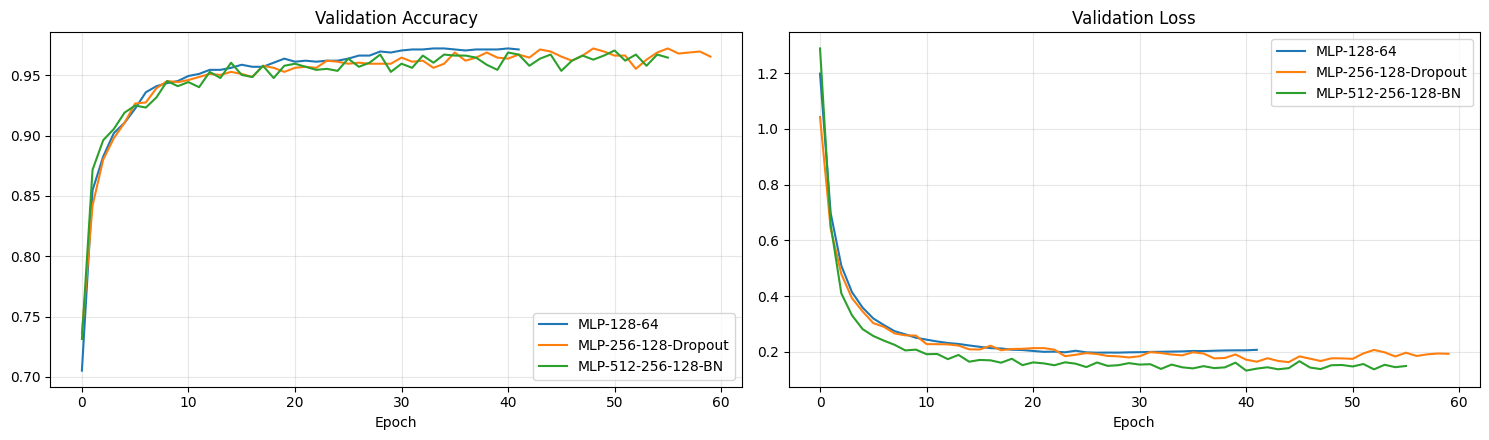

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, h in histories.items():
    axes[0].plot(h.history['val_accuracy'], label=name)
    axes[1].plot(h.history['val_loss'], label=name)
axes[0].set_title('Validation Accuracy'); axes[0].set_xlabel('Epoch')
axes[1].set_title('Validation Loss'); axes[1].set_xlabel('Epoch')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Langkah 6 - Evaluasi Model Terbaik pada Data Test
Model terbaik dipilih berdasarkan **akurasi validasi**; data test hanya dipakai sekali di akhir agar estimasi performa tidak bias.

In [8]:
best_name = df_res.loc[0, 'model']
best_model = trained[best_name]
print(f"Model terbaik: {best_name}\n")

y_prob = best_model.predict(X_test_s, verbose=0)
y_pred = y_prob.argmax(axis=1)
print(f"Akurasi Test : {accuracy_score(y_test, y_pred):.4f}")
print(f"F1 Macro Test: {f1_score(y_test, y_pred, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

Model terbaik: MLP-256-128-Dropout

Akurasi Test : 0.9789
F1 Macro Test: 0.9789

              precision    recall  f1-score   support

           A      0.970     0.970     0.970        33
           B      0.977     0.913     0.944        46
           C      0.977     0.977     0.977        44
           D      0.980     0.980     0.980        49
           E      0.957     0.978     0.968        46
           F      1.000     0.977     0.988        43
           G      0.956     0.977     0.966        44
           H      1.000     0.976     0.988        42
           I      1.000     1.000     1.000        53
           J      1.000     0.980     0.990        51
           K      1.000     1.000     1.000        39
           L      0.979     0.939     0.958        49
           M      0.964     1.000     0.981        53
           N      1.000     0.962     0.981        53
           O      1.000     1.000     1.000        46
           P      0.981     0.962     0.971        53


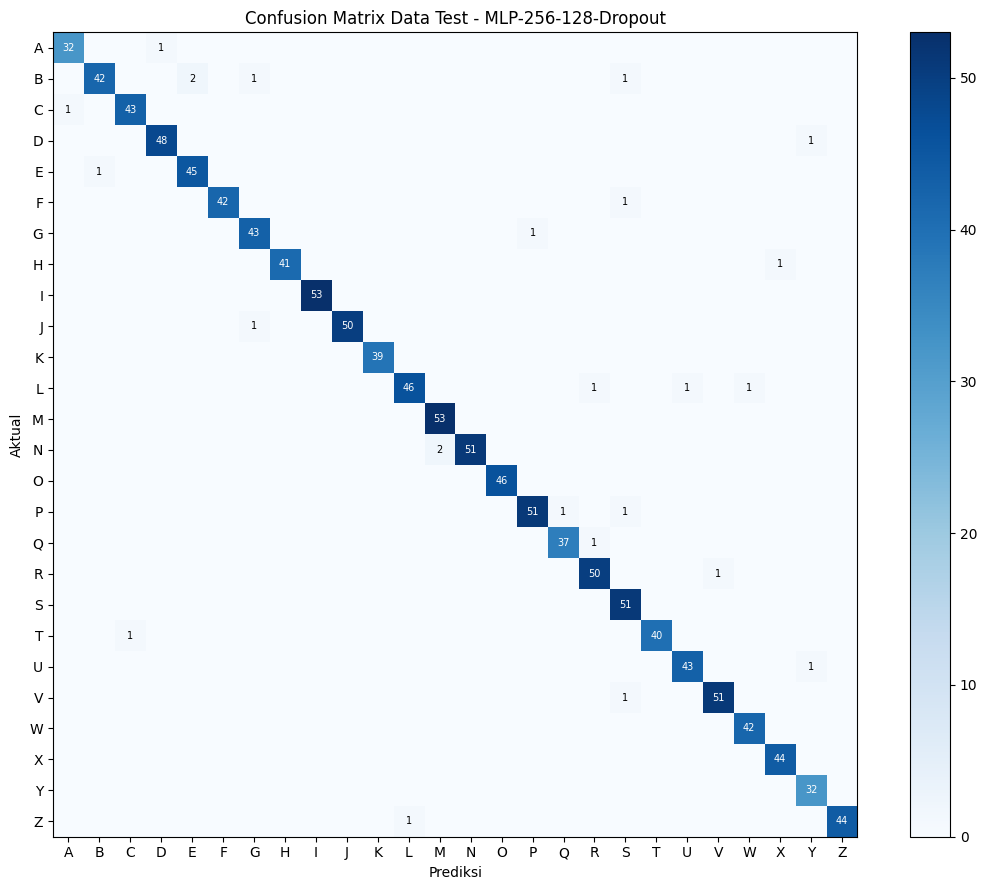

Pasangan huruf yang paling sering tertukar (aktual -> prediksi):
  N -> M: 2 sampel
  B -> E: 2 sampel
  Z -> L: 1 sampel
  V -> S: 1 sampel
  U -> Y: 1 sampel


In [9]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(class_names)), class_names)
ax.set_yticks(range(len(class_names)), class_names)
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
ax.set_title(f'Confusion Matrix Data Test - {best_name}')
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], class_names[i], class_names[j]) for i in range(26) for j in range(26) if off[i, j]), reverse=True)[:5]
print("Pasangan huruf yang paling sering tertukar (aktual -> prediksi):")
for n, a, p in pairs:
    print(f"  {a} -> {p}: {n} sampel")

### Langkah 7 - Menyimpan Artefak Deployment
Artefak disimpan ke `bisindo-project/`. Model disimpan dengan `include_optimizer=False` karena *state* optimizer tidak diperlukan untuk inferensi. File `hand_landmarker.task` (model deteksi tangan MediaPipe) juga disalin karena server harus mengekstraksi landmark dari gambar upload.

In [10]:
ART = Path('bisindo-project')
ART.mkdir(exist_ok=True)

best_model.save(ART / 'bisindo_model.h5', include_optimizer=False)
with open(ART / 'scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
with open(ART / 'labels.json', 'w') as f:
    json.dump(class_names, f)
shutil.copy('../UTS_Bisindo_Klasterisasi_Kelompok-1/DBScan/hand_landmarker.task', ART / 'hand_landmarker.task')

for f in sorted(ART.glob('*')):
    if f.is_file():
        print(f"  {f.name:24s} {f.stat().st_size / 1e6:7.3f} MB")

  app.py                     0.009 MB
  bisindo_model.h5           0.299 MB
  Dockerfile                 0.001 MB
  hand_landmarker.task       7.819 MB
  labels.json                0.000 MB
  README.md                  0.001 MB
  requirements.txt           0.000 MB
  scaler.pkl                 0.004 MB


#### Verifikasi Artefak

In [11]:
m2 = tf.keras.models.load_model(ART / 'bisindo_model.h5', compile=False)
with open(ART / 'scaler.pkl', 'rb') as f:
    s2 = pickle.load(f)
labels2 = json.load(open(ART / 'labels.json'))

pred2 = m2.predict(s2.transform(X_test), verbose=0).argmax(axis=1)
print(f"Prediksi identik dengan model di memori: {np.array_equal(pred2, y_pred)}")
print(f"Contoh 10 prediksi: {[labels2[i] for i in pred2[:10]]}")
print(f"Label asli        : {[class_names[i] for i in y_test[:10]]}")

Prediksi identik dengan model di memori: True
Contoh 10 prediksi: ['T', 'N', 'Q', 'F', 'G', 'G', 'I', 'Y', 'B', 'G']
Label asli        : ['T', 'N', 'Q', 'F', 'G', 'G', 'I', 'Y', 'B', 'G']


### Langkah 8 - Aplikasi Flask (`app.py`)
Struktur folder proyek deployment:
```
bisindo-project/
├── app.py                 # server Flask + ekstraksi landmark MediaPipe
├── requirements.txt       # library (versi dikunci sama dengan training)
├── Dockerfile             # Dockerfile standar praktikum + libegl1/libgles2
├── README.md              # konfigurasi Space (sdk: docker, app_port: 7860)
├── bisindo_model.h5
├── scaler.pkl
├── labels.json
└── hand_landmarker.task
```

Perbedaan utama dengan `app.py` Day vs Night ada pada fungsi *preprocessing*: HOG diganti dengan `extract_features()` yang merupakan salinan logika `extract_landmarks_from_image()` dari `extract_features.py` (urutan tangan primer/sekunder, translasi ke *wrist*, skala telapak, *zero-padding*, *flag* dua tangan). Konfigurasi `HandLandmarker` juga disamakan (`num_hands=2`, *confidence* 0.15). Fitur tambahan:
* Visualisasi kerangka landmark tangan pada gambar hasil upload.
* Top-3 huruf beserta probabilitasnya.
* Opsi **mirror** untuk foto dari kamera depan (dataset dinormalisasi ke orientasi tidak ter-*mirror*).
* Endpoint JSON `/api/predict`; jika tangan tidak terdeteksi, server mengembalikan status 422 dengan pesan yang jelas.

In [12]:
print((ART / 'app.py').read_text(encoding='utf-8'))

import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import base64
import json
import pickle

import cv2
import mediapipe as mp
import numpy as np
import tensorflow as tf
from flask import Flask, jsonify, render_template_string, request
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

app = Flask(__name__)
app.config["MAX_CONTENT_LENGTH"] = 10 * 1024 * 1024  # batas upload 10 MB

# Load Model, Scaler, Label, dan Hand Landmarker
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(BASE_DIR, "bisindo_model.h5")
SCALER_PATH = os.path.join(BASE_DIR, "scaler.pkl")
LABELS_PATH = os.path.join(BASE_DIR, "labels.json")
LANDMARKER_PATH = os.path.join(BASE_DIR, "hand_landmarker.task")

model = tf.keras.models.load_model(MODEL_PATH, compile=False)
with open(SCALER_PATH, "rb") as f:
    scaler = pickle.load(f)
with open(LABELS_PATH) as f:
    LABELS = json.load(f)

# Konfigurasi detektor sama dengan saat ekstraksi datase

### Langkah 9 - `requirements.txt` dan `Dockerfile`
* `requirements.txt` menambahkan **`mediapipe`**, dan `scikit-image` tidak lagi diperlukan karena HOG tidak dipakai.
* `Dockerfile` memakai konfigurasi standar praktikum, ditambah paket sistem **`libegl1`** dan **`libgles2`**. Tanpa kedua paket ini container gagal dijalankan dengan error `OSError: libEGL.so.1: cannot open shared object file` karena MediaPipe Tasks membutuhkan pustaka EGL/OpenGL ES (ditemukan saat pengujian Docker lokal).

In [13]:
print((ART / 'requirements.txt').read_text())
print((ART / 'Dockerfile').read_text())

flask==3.1.3
tensorflow-cpu==2.21.0
numpy==2.2.6
scikit-learn==1.7.0
mediapipe==1.2.3
opencv-python-headless==4.12.0.88
gunicorn

# Base Image Python 3.11 Slim
# (modul memakai 3.9, tetapi TensorFlow 2.21 yang dipakai saat training membutuhkan Python >= 3.10)
FROM python:3.11-slim

# Install Library Sistem untuk OpenCV (Debian Bookworm/Trixie Compatible)
# + libegl1 & libgles2: dibutuhkan MediaPipe Tasks (Hand Landmarker)
RUN apt-get update && apt-get install -y \
    libgl1 \
    libglib2.0-0 \
    libegl1 \
    libgles2 \
    && rm -rf /var/lib/apt/lists/*

# Setup User Non-Root (Standar Keamanan HF)
RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH"

# Setup Direktori Kerja
WORKDIR /app

# Install Dependencies
COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy File Aplikasi
COPY --chown=user . /app

# Expose Port & Jalankan
EXPOSE 7860
CMD ["python", "app.py"]



### Langkah 10 - Pengujian Docker Lokal
```bash
cd bisindo-project
docker build -t bisindo-classifier .
docker run --rm -p 7860:7860 bisindo-classifier
```

**Hasil pengujian lokal:**
* Build pertama dengan Dockerfile standar praktikum berhasil, tetapi container gagal saat memuat MediaPipe (`OSError: libEGL.so.1`). Setelah `libegl1` dan `libgles2` ditambahkan, container berjalan normal dengan log `System Loaded Successfully` (ukuran image ±3,7 GB).
* Sebanyak 52 citra asli dataset BISINDO (2 citra non-*flip* per huruf) dikirim ke `/api/predict`. Hasilnya **50 diprediksi benar**, 2 citra tidak terdeteksi tangannya oleh MediaPipe (huruf A dan K, yaitu citra yang juga gagal terdeteksi saat pembuatan dataset), dan **tidak ada salah prediksi** pada citra yang tangannya terdeteksi. Pengujian ini memastikan *pipeline* ekstraksi fitur di server identik dengan *pipeline* pembuatan dataset (catatan: citra uji berasal dari folder dataset, sehingga ini adalah uji konsistensi *pipeline*, bukan pengganti evaluasi data test di Langkah 6).
* Contoh respon JSON:

```json
{"confidence": 1.0, "huruf": "Z", "jumlah_tangan": 1,
 "top3": [{"huruf": "Z", "prob": 1.0}, {"huruf": "V", "prob": 0.0}, {"huruf": "G", "prob": 0.0}]}
```

### Langkah 11 - Deploy ke Hugging Face Spaces
1. **Create Space**: nama `bisindo-classifier-254107023005`, SDK **Docker** (*Blank*), lisensi MIT, *Public*.
2. **Clone, salin file, push**:

```bash
git lfs install
git clone https://huggingface.co/spaces/USERNAME_HF/bisindo-classifier-254107023005
cd bisindo-classifier-254107023005

# .gitattributes bawaan Space sudah men-track *.h5 dan *.pkl,
# tetapi belum *.task, sehingga harus ditambahkan agar file biner diterima
git lfs track "*.task"

cp ../bisindo-project/{app.py,requirements.txt,Dockerfile,README.md,bisindo_model.h5,scaler.pkl,labels.json,hand_landmarker.task} .
git add .
git commit -m "Deploy aplikasi BISINDO ke HF"
git push      # Username: username HF, Password: Access Token (Write)
```

3. Tunggu status **Building** → **Running**, lalu buka `https://USERNAME_HF-bisindo-classifier-254107023005.hf.space`.

> **Kendala deployment ke Hugging Face:** saat Space dibuat, Hugging Face menolak dengan pesan *"Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription"*. Docker Space kini hanya tersedia untuk akun **PRO**, sehingga deployment dilakukan sampai tahap **container Docker yang dijalankan secara lokal**. Image Docker yang sama persis inilah yang akan dibangun Hugging Face, jadi langkah 1–3 di atas tetap berlaku begitu akun PRO tersedia.

### Hasil Akhir: Aplikasi BISINDO Berjalan di Container Docker
Container dijalankan dengan `docker run -d --name bisindo-app -p 7861:7860 bisindo-classifier` dan diakses melalui `http://localhost:7861`. Garis hijau pada gambar adalah kerangka landmark tangan primer yang dideteksi MediaPipe di dalam container.

**Halaman utama**

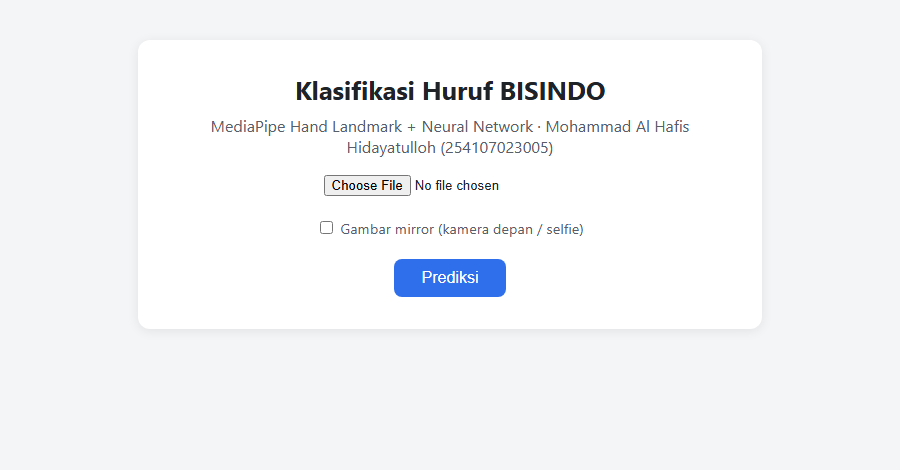

**Hasil prediksi huruf B**

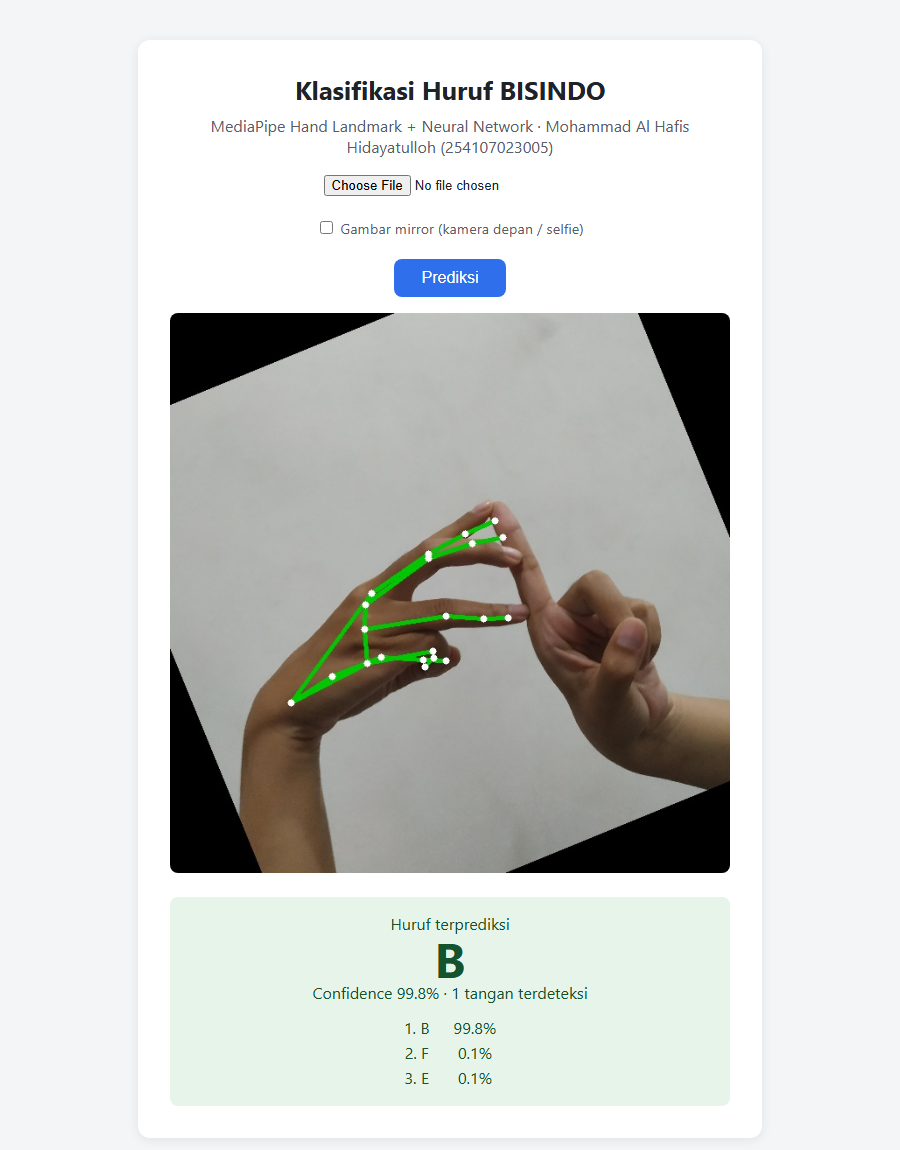

**Hasil prediksi huruf L**

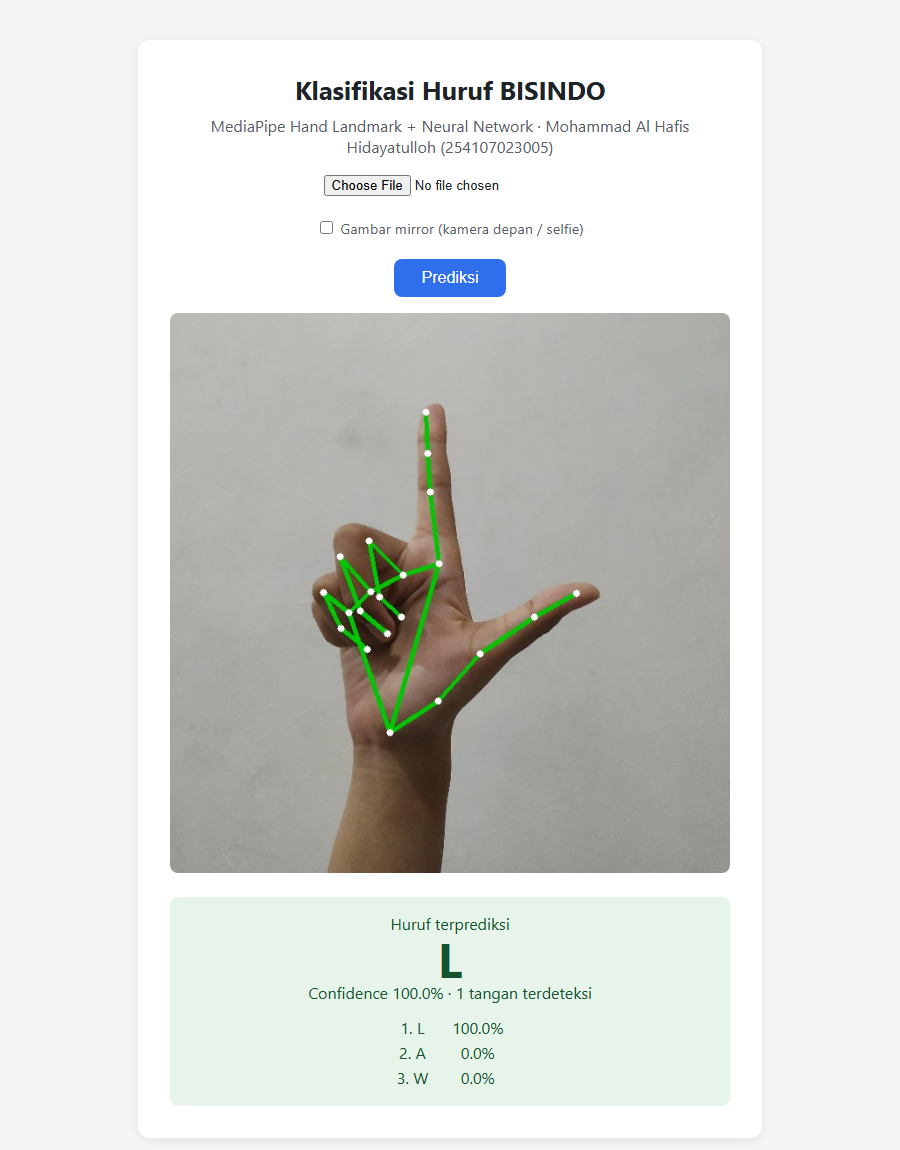

**Hasil prediksi huruf W**

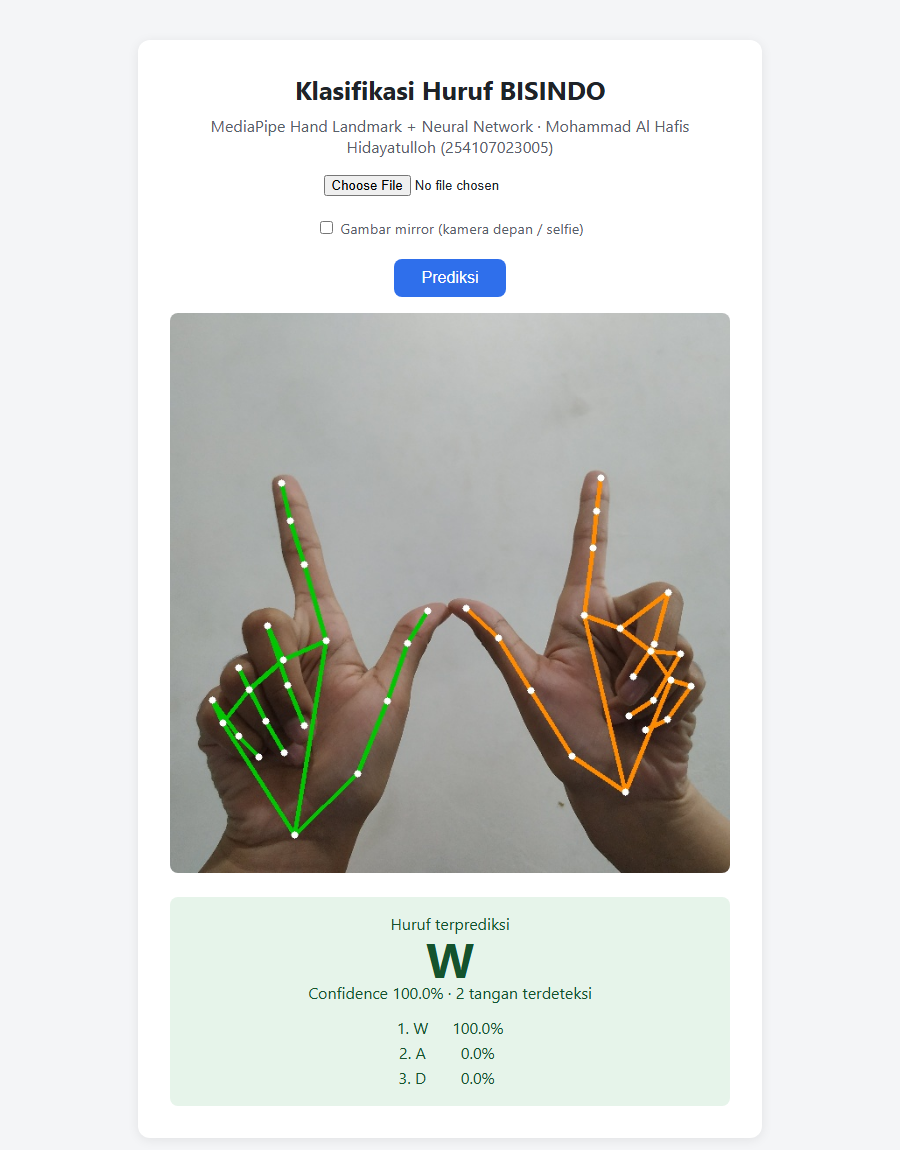

### Kesimpulan

1. *Pipeline* deployment dari Praktikum 2 berhasil diterapkan pada model proyek **klasifikasi huruf BISINDO**. Perbedaannya hanya pada tahap ekstraksi fitur (HOG diganti landmark tangan MediaPipe); struktur lainnya (artefak model `.h5` + scaler `.pkl`, Flask, Docker, Hugging Face) tetap sama.
2. Dari tiga arsitektur yang dibandingkan, **MLP-256-128-Dropout** memiliki akurasi validasi tertinggi (96,96%) dan mencapai **akurasi test 97,89%** dengan **F1-macro 0,979** pada 1.184 sampel. Arsitektur yang lebih besar dengan BatchNorm tidak memberi peningkatan karena 127 fitur landmark sudah sangat informatif. Kesalahan yang tersisa terjadi pada pasangan huruf yang bentuk tangannya mirip, misalnya **M ↔ N** dan **B ↔ E**.
3. Model berukuran sangat kecil (±0,3 MB), jauh lebih ringan daripada model Day vs Night (17,8 MB), karena input berupa 127 fitur landmark, bukan 34.596 fitur HOG.
4. Pengujian Docker lokal menemukan satu masalah lingkungan yang tidak terlihat saat menjalankan notebook, yaitu MediaPipe membutuhkan pustaka sistem EGL. Hal ini menegaskan pentingnya menguji container sebelum *deployment*: masalah semacam ini akan muncul sebagai *runtime error* di Hugging Face jika tidak diuji terlebih dahulu.
5. Deployment publik ke Hugging Face Spaces terkendala kebijakan baru yang mewajibkan langganan PRO untuk Docker Space, sehingga aplikasi dibuktikan berjalan pada container Docker lokal. File proyek siap di-*push* ke Space tanpa perubahan.
6. Keterbatasan: akurasi bergantung pada keberhasilan MediaPipe mendeteksi tangan. Pada citra yang tangannya terpotong, buram, atau gelap, aplikasi menampilkan pesan "tangan tidak terdeteksi" alih-alih memberikan prediksi yang salah.